# CP4, EDA: Detecção de Fraude em Cartão de Crédito

Este notebook documenta o passo a passo da análise exploratória e as decisões tomadas antes de treinar o modelo. A ideia é que qualquer pessoa consiga entender, só lendo aqui, o que foi feito e por que foi feito assim.

Problema: prever se uma transação de cartão de crédito é legítima ou fraudulenta, a partir de dados históricos.

Dataset: Credit Card Fraud Detection (Kaggle, mlg-ulb/creditcardfraud), com transações europeias de setembro de 2013. É um dataset diferente do Breast Cancer usado em aula.


## Escolha da stack

Antes de qualquer linha de código, seguem as decisões de ferramentas e por que cada uma foi escolhida.

1. Modelo: `MLPClassifier` do scikit-learn. O enunciado do trabalho pede um Multilayer Perceptron e proíbe TensorFlow, Keras ou PyTorch. O scikit-learn já implementa MLP de forma simples, integra bem com o resto do pipeline (ColumnTransformer, SMOTE, métricas) e evita a complexidade de configurar um framework de deep learning para um problema deste tamanho.
2. Balanceamento de classes: `imbalanced-learn` (SMOTE e RandomUnderSampler). O dataset tem menos de 0,2% de fraudes, então o modelo tende a simplesmente prever tudo como legítimo. SMOTE gera exemplos sintéticos da classe minoritária, e o undersampling reduz a classe majoritária, ambos aplicados somente no treino.
3. Rastreamento de experimentos: MLflow. Permite registrar parâmetros, métricas e o modelo treinado de cada execução, e depois comparar os experimentos numa interface, sem precisar montar uma planilha manual.
4. API de predição: FastAPI. Framework leve, com validação automática de entrada via Pydantic e documentação interativa gerada sozinha, o que facilita testar a API depois de pronta.

Com a stack definida, o passo seguinte é carregar e entender os dados.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carregando os dados (mesmo caminho usado pelo treino em src/train.py)
DATA_PATH = Path.cwd().parent / "data" / "raw" / "creditcard.csv"
df = pd.read_csv(DATA_PATH)

df.head()


Skipping, found downloaded files in "./creditcardfraud" (use force=True to force download)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Shape e colunas

Primeiro passo de qualquer EDA: entender o tamanho do dataset e o significado de cada coluna.

Definições:

- `Time`: segundos decorridos entre cada transação e a primeira transação do dataset. É um número contínuo, não um horário do relógio.
- `Amount`: valor monetário da transação.
- `V1` a `V28`: componentes gerados por PCA a partir dos dados originais da transação. Foram anonimizados assim por motivo de confidencialidade (não sabemos o que cada um representa individualmente), mas continuam sendo variáveis numéricas úteis para o modelo.
- `Class`: variável alvo. 0 significa transação legítima e 1 significa fraude.


In [2]:
print("Shape:", df.shape)
print("Colunas:")
print(list(df.columns))


Shape: (284807, 31)
Colunas:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


## 2. Valores ausentes

Antes de treinar qualquer modelo é preciso saber se existem valores faltando, porque o `MLPClassifier` do scikit-learn não aceita `NaN` como entrada. Se houvesse valores ausentes, seria necessário decidir uma estratégia de imputação (média, mediana, remoção de linhas) antes do treino.

Este dataset é conhecido por não ter valores nulos. A célula abaixo confirma isso no arquivo local usado, para não assumir esse fato sem checar.


In [3]:
missing = df.isna().sum().sort_values(ascending=False)
missing[missing > 0], missing.sum()


(Series([], dtype: int64), np.int64(0))

## 3. Distribuição da classe

Aqui verificamos o quanto o dataset é desbalanceado, ou seja, a diferença de tamanho entre a classe 0 (legítima) e a classe 1 (fraude).

Por que isso importa: fraudes são raras, historicamente bem abaixo de 1% das transações. Um modelo que sempre responde 'legítima' já acerta mais de 99% das vezes e teria acurácia altíssima, mas seria inútil, porque nunca identificaria uma fraude de verdade.

Por isso a acurácia sozinha não é usada como critério de seleção do modelo neste projeto. As métricas priorizadas são recall, precision, F1-score e ROC-AUC da classe fraude, calculadas mais adiante durante o treino.


Class
0    284315
1       492
Name: count, dtype: int64
Fraudes: 0.1727%


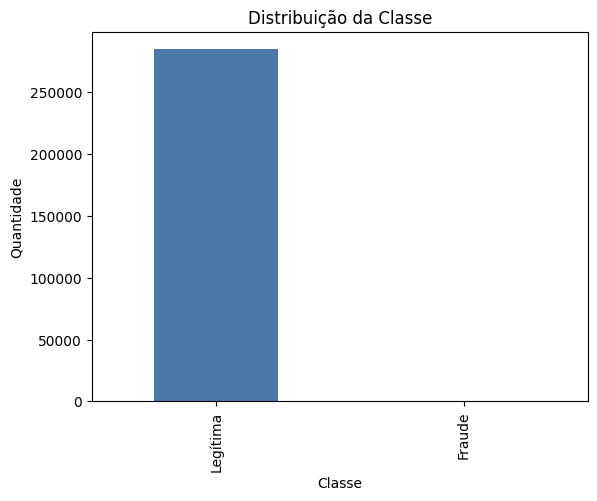

In [4]:
class_counts = df["Class"].value_counts().sort_index()
fraud_pct = class_counts.get(1, 0) / len(df) * 100
print(class_counts)
print(f"Fraudes: {fraud_pct:.4f}%")

ax = class_counts.rename({0: "Legítima", 1: "Fraude"}).plot(kind="bar", title="Distribuição da Classe", color=["#4C78A8", "#F58518"])
ax.set_xlabel("Classe")
ax.set_ylabel("Quantidade")
plt.show()


## 4. Estatísticas de Time e Amount, e decisão de pré-processamento

As colunas `V1` a `V28` já saem do PCA em uma escala parecida entre si, então não precisam de tratamento adicional. Já `Time` e `Amount` são campos brutos, em escalas bem diferentes uma da outra (segundos versus valores monetários), o que pode atrapalhar o treino do MLP.

Decisão: padronizar apenas `Time` e `Amount` com `StandardScaler`, mantendo as demais colunas como estão. Esse mesmo padronizador (`preprocessor`) é salvo depois do treino e reaplicado em qualquer dado novo enviado para predição, garantindo que o treino e a API usem exatamente a mesma transformação.


In [5]:
df[["Time", "Amount"]].describe()


,Time,Amount
count,284807.000000,284807.000000
mean,94813.859575,88.349619
std,47488.145955,250.120109
min,0.000000,0.000000
25%,54201.500000,5.600000
50%,84692.000000,22.000000
75%,139320.500000,77.165000
max,172792.000000,25691.160000


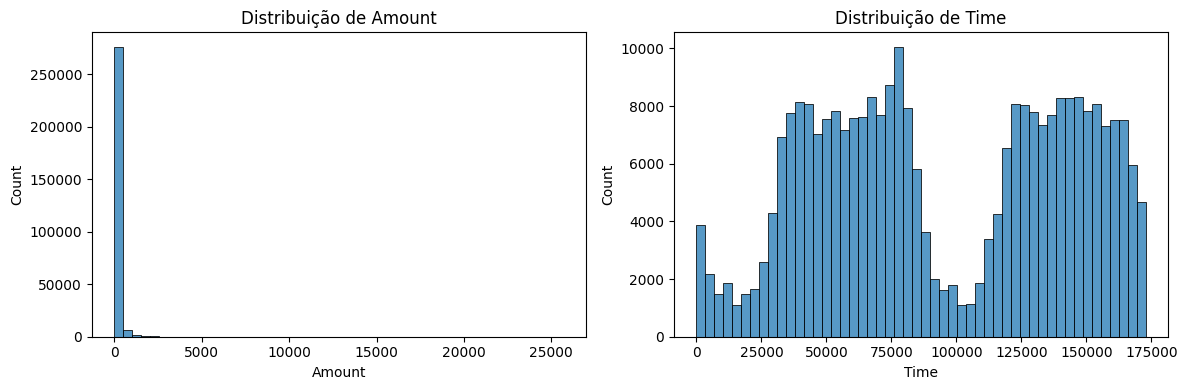

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Amount"], bins=50, ax=axes[0])
axes[0].set_title("Distribuição de Amount")
sns.histplot(df["Time"], bins=50, ax=axes[1])
axes[1].set_title("Distribuição de Time")
plt.tight_layout()
plt.show()


## 5. Processo planejado para o treino

Com a análise exploratória feita, este é o passo a passo que será executado em `src/train.py` para treinar e selecionar o modelo:

1. Separar os dados em treino, validação e teste, de forma estratificada, para manter a mesma proporção de fraudes em cada parte.
2. Ajustar o `StandardScaler` (definido na seção 4) somente com os dados de treino, e aplicar essa mesma transformação em validação e teste.
3. Aplicar SMOTE ou undersampling somente nos dados de treino já transformados, nunca em validação ou teste, para não vazar informação sintética para a avaliação do modelo.
4. Treinar cinco configurações de MLP, variando número de camadas, neurônios, taxa de aprendizado, função de ativação e estratégia de balanceamento.
5. Para cada configuração, testar diferentes limiares de decisão na validação e escolher o limiar que maximiza o F1-score da classe fraude, entre os limiares que atingem um recall mínimo aceitável.
6. Registrar no MLflow, para cada execução: os parâmetros usados, as métricas obtidas (accuracy, precision, recall, F1-score, ROC-AUC) e o modelo treinado como artifact.
7. Comparar as cinco execuções na interface do MLflow e escolher a de maior F1-score entre as que atingem o recall mínimo, usando ROC-AUC como critério de desempate.
8. Salvar o modelo escolhido e o preprocessador como artifacts, para serem carregados depois pela API de predição.


## 6. Conclusões da análise exploratória

- O problema é de classificação binária, com desbalanceamento forte entre as classes.
- Não há valores ausentes a tratar.
- `V1` a `V28` já estão em escala compatível entre si, e não precisam de padronização.
- `Time` e `Amount` precisam ser padronizados antes do treino.
- A seleção do melhor modelo deve priorizar recall, precision e F1-score da classe fraude, não a acurácia geral.
